<a href="https://colab.research.google.com/github/fadeeva/normal_projects/blob/master/Pesticide%20Usage%20in%20the%20United%20States/notebooks/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

plt.style.use('ggplot')

In [16]:
import kagglehub

path = kagglehub.dataset_download('konradb/pesticide-usage-in-the-united-states')

print('Path to dataset files:', path)

Using Colab cache for faster access to the 'pesticide-usage-in-the-united-states' dataset.
Path to dataset files: /kaggle/input/pesticide-usage-in-the-united-states


In [17]:
! ls {path}

epest_county_estimates.csv


In [31]:
df_full = pd.read_csv(f'{path}/epest_county_estimates.csv')
df_full.columns = [col.lower() for col in df_full.columns]
df_full.head()

,compound,year,state_fips_code,county_fips_code,epest_low_kg,epest_high_kg
0,"2,4-D",2019,1,1,3955.7,3951.6
1,"2,4-D",2019,1,3,2519.1,2901.5
2,"2,4-D",2019,1,5,5411.8,5639.1
3,"2,4-D",2019,1,7,1404.8,1527.6
4,"2,4-D",2019,1,9,17250.2,17384.7


In [32]:
df_full.shape

(9562214, 6)

In [33]:
df_full.describe()

,year,state_fips_code,county_fips_code,epest_low_kg,epest_high_kg
count,9.562214e+06,9.562214e+06,9.562214e+06,6.120573e+06,9.560938e+06
mean,2.005740e+03,3.067290e+01,9.611447e+01,1.815101e+03,1.374774e+03
std,7.829087e+00,1.479499e+01,8.677781e+01,2.713941e+04,2.243092e+04
min,1.992000e+03,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,1.999000e+03,1.900000e+01,3.500000e+01,2.000000e+00,2.700000e+00
50%,2.006000e+03,2.900000e+01,7.700000e+01,2.020000e+01,2.370000e+01
75%,2.013000e+03,4.500000e+01,1.310000e+02,2.005000e+02,1.907000e+02
max,2.019000e+03,5.600000e+01,8.100000e+02,9.623804e+06,9.623804e+06


In [34]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9562214 entries, 0 to 9562213
Data columns (total 6 columns):
 #   Column            Dtype  
---  ------            -----  
 0   compound          object 
 1   year              int64  
 2   state_fips_code   int64  
 3   county_fips_code  int64  
 4   epest_low_kg      float64
 5   epest_high_kg     float64
dtypes: float64(2), int64(3), object(1)
memory usage: 437.7+ MB


In [35]:
df = df_full.copy()

In [36]:
missing = pd.DataFrame(index=df.columns)

missing['Null'] = df.isnull().sum()
missing['%'] = np.round(df.isnull().mean() * 100, 2)

missing

,Null,%
compound,0,0.00
year,0,0.00
state_fips_code,0,0.00
county_fips_code,0,0.00
epest_low_kg,3441641,35.99
epest_high_kg,1276,0.01


In [39]:
df = df.dropna(axis=0)

In [40]:
df[['year', 'compound', 'state_fips_code', 'county_fips_code']].nunique()

,0
year,28
compound,533
state_fips_code,48
county_fips_code,267


Text(0.5, 1.0, 'high - low, kg')

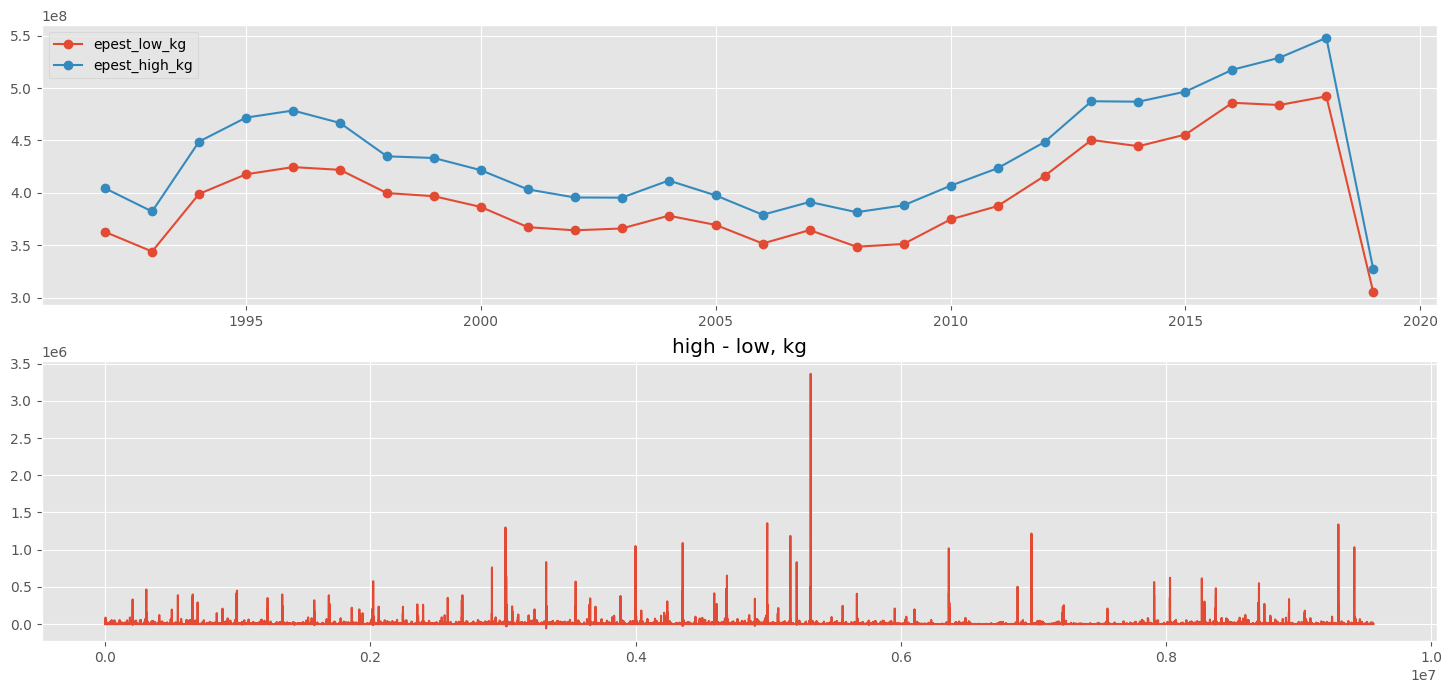

In [69]:
epest = df.groupby('year').agg({
    'epest_low_kg': 'sum',
    'epest_high_kg': 'sum'
})

fig, axs = plt.subplots(2, 1, figsize=(18, 8))
axs[0].plot(epest, marker='o')
axs[0].legend(['epest_low_kg', 'epest_high_kg'])

diff = df['epest_high_kg'] - df['epest_low_kg']
axs[1].plot(diff)
axs[1].set_title('high - low, kg')


In [70]:
diff.describe()

,0
count,6.119297e+06
mean,1.712447e+02
std,3.304319e+03
min,-5.829740e+04
25%,0.000000e+00
50%,0.000000e+00
75%,2.030000e+01
max,3.361807e+06


In [76]:
df[df['epest_low_kg'] == df['epest_low_kg'].max()]

,compound,year,state_fips_code,county_fips_code,epest_low_kg,epest_high_kg
8784587,SULFUR,1998,6,19,9623803.9,9623803.9


In [52]:
agg = df.groupby(['year', 'compound']).agg({
    'epest_low_kg': 'sum',
    'epest_high_kg': 'sum'
}).reset_index()

top_low = (agg.sort_values(['year', 'epest_low_kg'], ascending=[True, False])
              .groupby('year').head(10))

top_high = (agg.sort_values(['year', 'epest_high_kg'], ascending=[True, False])
               .groupby('year').head(10))

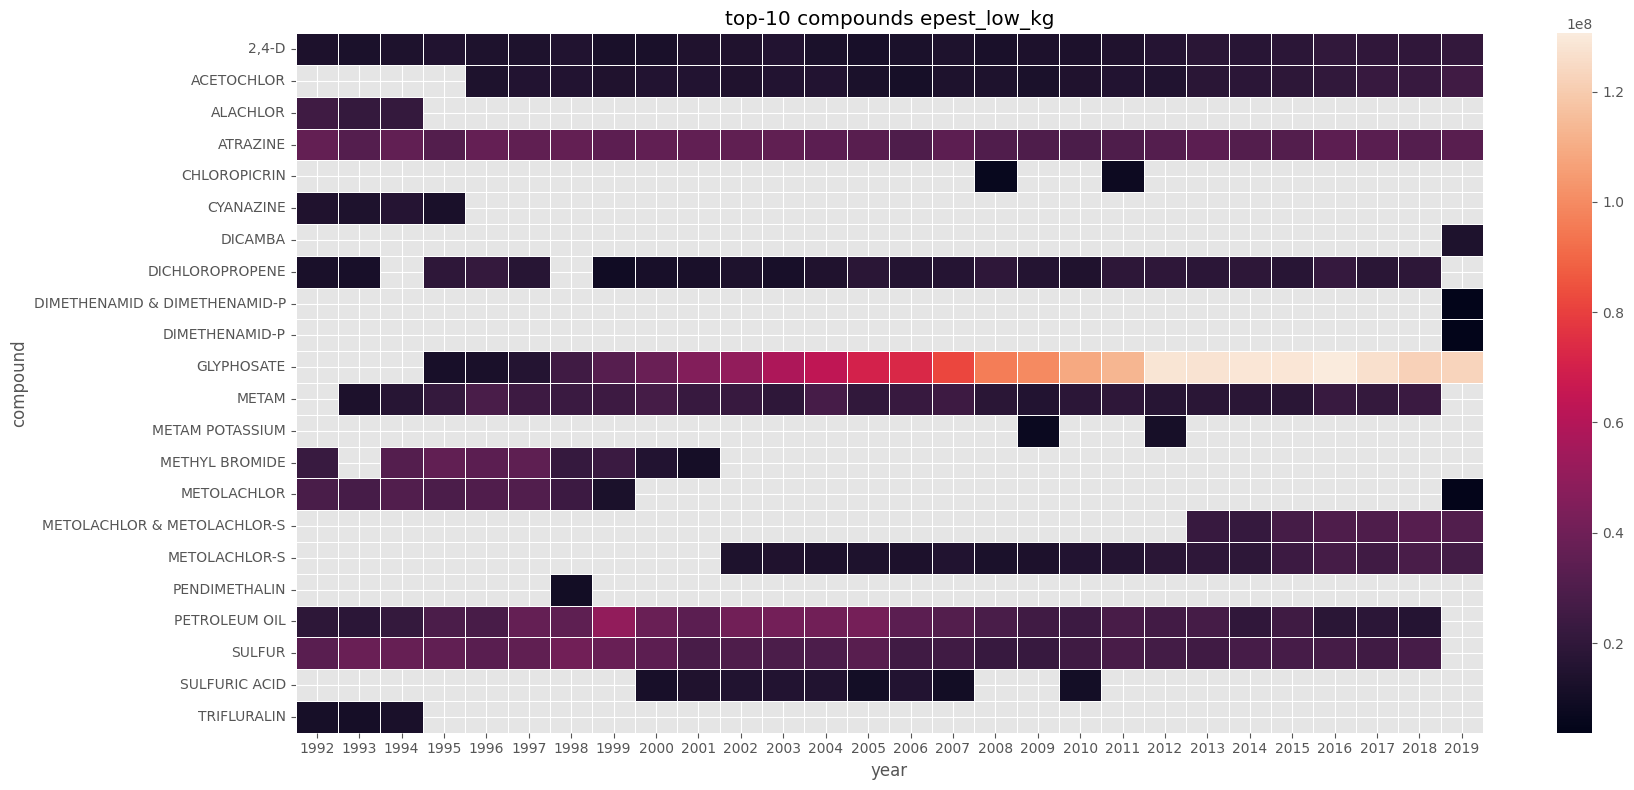

In [53]:
pivot = top_low.pivot_table(index='compound', columns='year',
                            values='epest_low_kg', aggfunc='sum')

plt.figure(figsize=(18, 8))
sns.heatmap(pivot, fmt='.0f', linewidths=.5)
plt.title('top-10 compounds epest_low_kg')

plt.tight_layout()


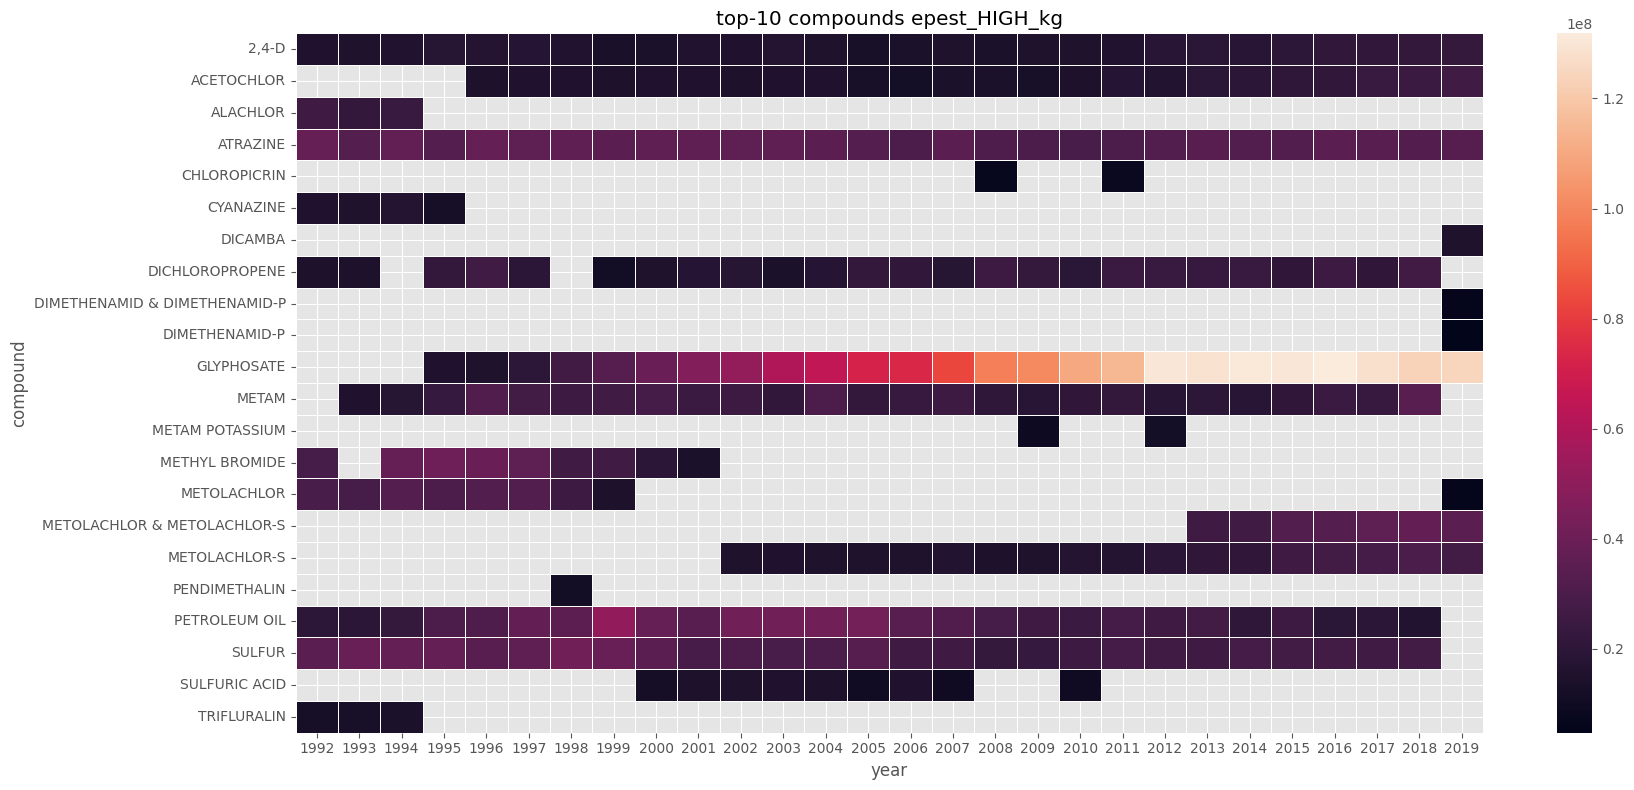

In [54]:
pivot = top_low.pivot_table(index='compound', columns='year',
                            values='epest_high_kg', aggfunc='sum')

plt.figure(figsize=(18, 8))
sns.heatmap(pivot, fmt='.0f', linewidths=.5)
plt.title('top-10 compounds epest_HIGH_kg')
plt.tight_layout()

In [60]:
df.groupby(['compound', 'year']).agg({
    'epest_low_kg': 'sum',
    'epest_high_kg': 'sum'
}).loc['SULFUR']

,epest_low_kg,epest_high_kg
year,,
1992,33415760.2,34928363.0
1993,38027329.8,38691205.5
1994,37049638.2,37661980.4
1995,35900860.0,37798897.4
1996,33151958.2,34270690.8
1997,35014559.8,36311028.7
1998,40615274.7,41539698.2
1999,37853691.1,38665265.4
2000,34058797.7,35014719.7
